# Training RL using Co-design Gym

In this notebook, we will train a simple implementation of PPO from CleanRL (optimized for Mujoco) on a CPU version of Walker2D.

Estimated running time: <20 min

## Setup
Make sure you ran https://github.com/camral/codesign-gym/tree/main#basic-install beforehand.
Let's set up some helpers:

In [1]:
# import dependencies
import os
import random
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image as ShowImage, display
from PIL import Image

sys.path.insert(0, os.path.abspath("helpers"))  # tutorial helper modules live in notebooks/helpers
from ppo_mujoco import evaluate_policy, load_result, make_env, train_ppo

ENV_ID = "Walker2d-v4"
os.makedirs("runs", exist_ok=True)

random_seed = 0
random.seed(random_seed)
np.random.seed(random_seed)
torch.manual_seed(random_seed)

# load the Walker2D env with CPU (on the CPU, make_env picks native C MuJoCo physics, which is much faster than Warp)
# 2 parallel copies so we can show two different bodies side by side; rgb_array lets us render frames.
env, base = make_env(ENV_ID, 2, device="cpu", render_mode="rgb_array")
print("observation space:", env.single_observation_space)
print("action space:     ", env.single_action_space)
print("embodiment space: ", env.embodiment_space)
print("base design:      ", base)

# A design is 12 offsets in [-1, 1] (each step of 1.0 is 0.163 m). Slots 3, 5, 8, 10 stretch the
# right thigh, right shin, left thigh and left shin downwards, i.e. longer legs.
long_legs = base.copy()
long_legs[[3, 5, 8, 10]] = 0.5
print("long-leg design:  ", long_legs)

[codesign-gym] make_vec('Walker2d-v4', num_envs=2): instantiating
[walker2d] WARNING: torso_upper_offsettable_z: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[walker2d] WARNING: torso_lower_offsettable_z: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[walker2d] WARNING: foot_toe_offsettable_x: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[walker2d] WARNING: foot_left_toe_offsettable_x: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[codesign-gym] make_vec('Walker2d-v4', num_envs=2): success
observation space: Box(-inf, inf, (17,), float32)
action space:      Box(-1.0, 1.0, (6,), float32)
embodiment space:  Box(-1.0, 1.0, (12,), float32)
base design:       [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
long-leg design:   [0.  0.  0.  0.5 0.  0.5 0.  0.  0.5 0.  0.5 0. ]


Codesign gym handles everything by flattening it into a vector. To see what different action, observation, and embodiment space values mean, go to docs>envs.

## Different bodies

In codesign gym, we can change the design of the bodies. As an example, you can load an image of the normal Walker2D versus a Walker2D with longer legs.

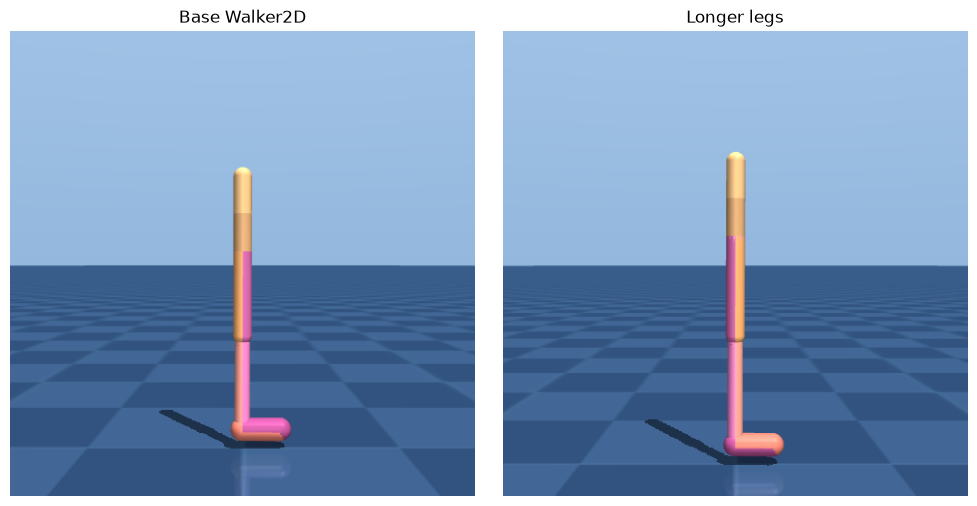

In [2]:
# render image of normal Walker2D vs Walker2D with longer legs.
# One reset gives each copy its own design: copy 0 = base, copy 1 = longer legs.
obs, rejected, info = env.reset(seed=random_seed, embodiment=np.stack([base, long_legs]))
assert not rejected.any()

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, idx, title in zip(axes, (0, 1), ("Base Walker2D", "Longer legs")):
    ax.imshow(env.render(env_idx=idx))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()
env.close()

## Training on different embodiments

In `helpers/ppo_mujoco.py`, there is a version of PPO that takes a specific design to train on. Let's try training on the longer-leg walker with that.

Training should take about 3 minutes on a MacBook Pro M2 (~6000 steps per second).

[codesign-gym] make_vec('Walker2d-v4', num_envs=16): instantiating
[walker2d] WARNING: torso_upper_offsettable_z: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[walker2d] WARNING: torso_lower_offsettable_z: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[walker2d] WARNING: foot_toe_offsettable_x: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[walker2d] WARNING: foot_left_toe_offsettable_x: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[codesign-gym] make_vec('Walker2d-v4', num_envs=16): success
[Walker2d-v4] iter 10/488 step 20480 return 137.6 (n=12) SPS 1726
[Walker2d-v4] iter 20/488 step 40960 return 320.2 (n=8) SPS 1955
[Walker2d-v4] iter 30/488 step 61440 return 455.6 (n=14) SPS 2007
[Walker2d-v4] iter 40/488 step 81920 return 370.5 (n=12) SPS 1782
[Walker2d-v4] iter 50/488 step 102400 return 339.1 (n=13) SPS 1871
[Walker2d-v4] iter 60/488 step 122880 return 366.4 (n=10) SPS 1915
[Walker2d-v4] iter 70/488 step 1

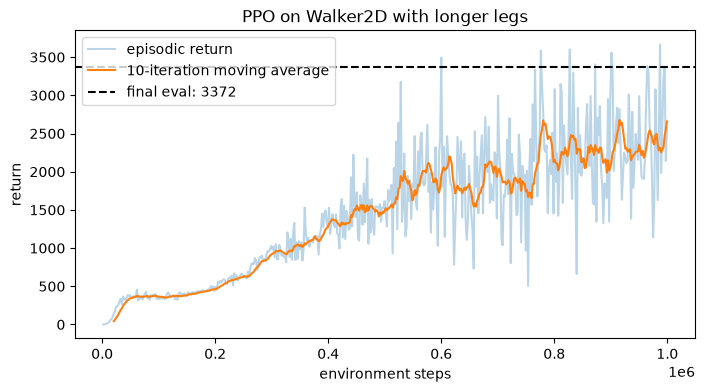

eval return on long legs: 3371.7 ± 567.1 (16 episodes)


In [3]:
# train longer leg walker on PPO for 1M env steps, showing a plot of the training curve at the end, saving the final checkpoint in runs/final.pt
# (Under 5 minutes on a laptop CPU. Progress is printed every 10 PPO iterations)
result = train_ppo(
    ENV_ID,
    embodiment=long_legs,
    total_timesteps=1_000_000,
    seed=random_seed,
    device="cpu",
    eval_episodes=16,            # deterministic evaluation on the long-leg design after training
    save_path="runs/final.pt",
    log_dir="runs",              # tensorboard logs, optional
)

# training curve: mean return of the episodes that finished in each PPO iteration
rows = [r for r in result.history if r["episodic_return"] is not None]
steps = np.array([r["global_step"] for r in rows])
returns = np.array([r["episodic_return"] for r in rows])
window = 10
smooth = np.convolve(returns, np.ones(window) / window, mode="valid")

plt.figure(figsize=(8, 4))
plt.plot(steps, returns, alpha=0.3, label="episodic return")
plt.plot(steps[window - 1:], smooth, label=f"{window}-iteration moving average")
plt.axhline(result.eval_returns.mean(), color="k", ls="--", label=f"final eval: {result.eval_returns.mean():.0f}")
plt.xlabel("environment steps")
plt.ylabel("return")
plt.title("PPO on Walker2D with longer legs")
plt.legend()
plt.show()
print(f"eval return on long legs: {result.eval_returns.mean():.1f} ± {result.eval_returns.std():.1f} (16 episodes)")

Note that this Walker2D has been optimized for CPU. Some of the Mujoco envs are optimized for Warp, and need to be rewritten a bit if you want to train on just CPU. Of course, when you build your own env, you can make it CPU-only.

The environment constructor, `make_vec` returns (env, base_embodiment) and the env is natively batched: obs, rewards and flags are torch.

When you want to use codesign gym with an existing RL package, the biggest change is adding in the embodiments. So when you build a wrapper for the resets, make sure to include embodiments.

Function that resets all embodiments to one uniform design (What we are doing here)
```
def full_reset(env, embodiment, seed=None) -> torch.Tensor:
    obs, rejected, info = env.reset(seed=seed, embodiment=embodiment)
    if bool(torch.as_tensor(rejected).any()):
        raise ValueError(f"embodiment rejected by the simulator: {embodiment}")
    return obs
```

You can also pass an array of designs for each parallel env to test multiple designs at once.
```
raw_obs, rejected, _ = envs.reset(embodiment=to_env_units(designs).cpu().numpy(),
                                                      options={"reset_mask": need_design})
```

That's all that's needed to get any RL algorithm that works with Gym working with Codesign Gym!

Cool, looks like it trained. Let's see this in action.

[codesign-gym] make_vec('Walker2d-v4', num_envs=1): instantiating
[walker2d] WARNING: torso_upper_offsettable_z: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[walker2d] WARNING: torso_lower_offsettable_z: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[walker2d] WARNING: foot_toe_offsettable_x: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[walker2d] WARNING: foot_left_toe_offsettable_x: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[codesign-gym] make_vec('Walker2d-v4', num_envs=1): success
episode return: 3730.7 over 201 frames


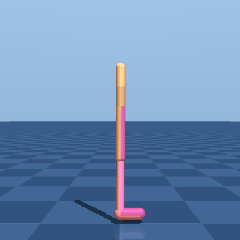

In [4]:
# generate video of the walker2d policy
def rollout_frames(policy, embodiment, max_steps=1000, frame_every=5, seed=random_seed):
    """Run one episode with `policy` (raw obs -> action) on `embodiment`; return (frames, episode return)."""
    render_env, _ = make_env(ENV_ID, 1, device="cpu", render_mode="rgb_array")
    try:
        obs, rejected, _ = render_env.reset(seed=seed, embodiment=embodiment)
        assert not rejected.any()
        frames, total = [render_env.render(env_idx=0)], 0.0
        for t in range(max_steps):
            action = torch.clamp(policy(obs), -1.0, 1.0)
            obs, reward, terminated, truncated, info = render_env.step(action)
            total += float(reward[0])
            if t % frame_every == 0:
                frames.append(render_env.render(env_idx=0))
            if bool(terminated[0] or truncated[0]):
                break
        return frames, total
    finally:
        render_env.close()


def save_gif(frames, path, frame_every=5, control_dt=0.008):
    """Write frames as a real-time GIF (half resolution to keep the file small) and display it."""
    images = [Image.fromarray(f[::2, ::2]) for f in frames]
    images[0].save(path, save_all=True, append_images=images[1:], duration=int(1000 * control_dt * frame_every), loop=0)
    display(ShowImage(filename=path))


frames, ep_return = rollout_frames(result.act, long_legs)
print(f"episode return: {ep_return:.1f} over {len(frames)} frames")
save_gif(frames, "runs/long_legs.gif")

## Same policy, different body?

Now, let's see what happens if we try to run the same policy on the base design.

policy was trained on design: [0.  0.  0.  0.5 0.  0.5 0.  0.  0.5 0.  0.5 0. ]
[codesign-gym] make_vec('Walker2d-v4', num_envs=1): instantiating
[walker2d] WARNING: torso_upper_offsettable_z: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[walker2d] WARNING: torso_lower_offsettable_z: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[walker2d] WARNING: foot_toe_offsettable_x: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[walker2d] WARNING: foot_left_toe_offsettable_x: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[codesign-gym] make_vec('Walker2d-v4', num_envs=1): success
episode return on the base body: 827.2


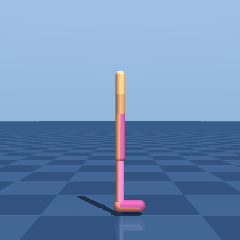

[codesign-gym] make_vec('Walker2d-v4', num_envs=16): instantiating
[walker2d] WARNING: torso_upper_offsettable_z: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[walker2d] WARNING: torso_lower_offsettable_z: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[walker2d] WARNING: foot_toe_offsettable_x: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[walker2d] WARNING: foot_left_toe_offsettable_x: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[codesign-gym] make_vec('Walker2d-v4', num_envs=16): success
Module _next_time_builder__locals___next_time_1cb22d2e 1cb22d2 load on device 'cuda:0' took 3.89 ms  (cached)
[codesign-gym] make_vec('Walker2d-v4', num_envs=16): instantiating
[walker2d] WARNING: torso_upper_offsettable_z: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[walker2d] WARNING: torso_lower_offsettable_z: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[walker2d] WARNING: foot_toe_o

In [5]:
# load the policy and render a rollout, also print the eval score average of 16 rollouts
policy = load_result("runs/final.pt")
print("policy was trained on design:", policy.embodiment)

# one rendered rollout on the base body
frames, ep_return = rollout_frames(policy.act, base)
print(f"episode return on the base body: {ep_return:.1f}")
save_gif(frames, "runs/base_body.gif")

# 16 deterministic rollouts on each body
base_returns = evaluate_policy(policy.act, ENV_ID, base, num_episodes=16, seed=random_seed)
long_returns = evaluate_policy(policy.act, ENV_ID, long_legs, num_episodes=16, seed=random_seed)
print(f"long legs (trained body): {long_returns.mean():.1f} ± {long_returns.std():.1f}")
print(f"base body (unseen):       {base_returns.mean():.1f} ± {base_returns.std():.1f}")

It should be pretty clear that the design matters a lot!

What if we use the parallel aspect of the codesign simulation?

Training both embodiments in parallel takes 3 minutes on a MacBook Pro M2 (~6000 steps per second).

[array([0. , 0. , 0. , 0.5, 0. , 0.5, 0. , 0. , 0.5, 0. , 0.5, 0. ],
      dtype=float32), array([0. , 0. , 0. , 0.5, 0. , 0.5, 0. , 0. , 0.5, 0. , 0.5, 0. ],
      dtype=float32), array([0. , 0. , 0. , 0.5, 0. , 0.5, 0. , 0. , 0.5, 0. , 0.5, 0. ],
      dtype=float32), array([0. , 0. , 0. , 0.5, 0. , 0.5, 0. , 0. , 0.5, 0. , 0.5, 0. ],
      dtype=float32), array([0. , 0. , 0. , 0.5, 0. , 0.5, 0. , 0. , 0.5, 0. , 0.5, 0. ],
      dtype=float32), array([0. , 0. , 0. , 0.5, 0. , 0.5, 0. , 0. , 0.5, 0. , 0.5, 0. ],
      dtype=float32), array([0. , 0. , 0. , 0.5, 0. , 0.5, 0. , 0. , 0.5, 0. , 0.5, 0. ],
      dtype=float32), array([0. , 0. , 0. , 0.5, 0. , 0.5, 0. , 0. , 0.5, 0. , 0.5, 0. ],
      dtype=float32), array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32), array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32), array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32), array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=f

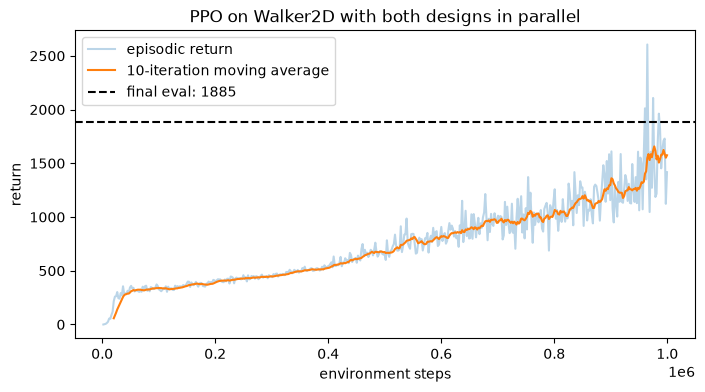

eval return: 1885.1 ± 934.1 (16 episodes)


In [6]:
both_designs = [long_legs]*8+[base]*8

print(both_designs)

result = train_ppo(
    ENV_ID,
    embodiment=both_designs,
    total_timesteps=1_000_000,
    seed=random_seed,
    device="cpu",
    eval_episodes=16,            # deterministic evaluation on the long-leg design after training
    save_path="runs/final_both.pt",
    log_dir="runs",              # tensorboard logs, optional
)

rows = [r for r in result.history if r["episodic_return"] is not None]
steps = np.array([r["global_step"] for r in rows])
returns = np.array([r["episodic_return"] for r in rows])
window = 10
smooth = np.convolve(returns, np.ones(window) / window, mode="valid")

plt.figure(figsize=(8, 4))
plt.plot(steps, returns, alpha=0.3, label="episodic return")
plt.plot(steps[window - 1:], smooth, label=f"{window}-iteration moving average")
plt.axhline(result.eval_returns.mean(), color="k", ls="--", label=f"final eval: {result.eval_returns.mean():.0f}")
plt.xlabel("environment steps")
plt.ylabel("return")
plt.title("PPO on Walker2D with both designs in parallel")
plt.legend()
plt.show()
print(f"eval return: {result.eval_returns.mean():.1f} ± {result.eval_returns.std():.1f} (16 episodes)")

policy was trained on design: [[0.  0.  0.  0.5 0.  0.5 0.  0.  0.5 0.  0.5 0. ]
 [0.  0.  0.  0.5 0.  0.5 0.  0.  0.5 0.  0.5 0. ]
 [0.  0.  0.  0.5 0.  0.5 0.  0.  0.5 0.  0.5 0. ]
 [0.  0.  0.  0.5 0.  0.5 0.  0.  0.5 0.  0.5 0. ]
 [0.  0.  0.  0.5 0.  0.5 0.  0.  0.5 0.  0.5 0. ]
 [0.  0.  0.  0.5 0.  0.5 0.  0.  0.5 0.  0.5 0. ]
 [0.  0.  0.  0.5 0.  0.5 0.  0.  0.5 0.  0.5 0. ]
 [0.  0.  0.  0.5 0.  0.5 0.  0.  0.5 0.  0.5 0. ]
 [0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0. ]]
[codesign-gym] make_vec('Walker2d-v4', num_envs=1): instantiating
[walker2d] WARNING: torso_upper_offsettable_z: 0.200 m undeformed, 0.037 m at its short

episode return on the base body: 3254.1


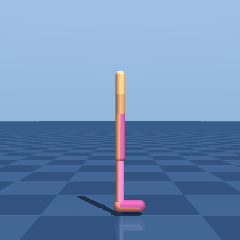

[codesign-gym] make_vec('Walker2d-v4', num_envs=1): instantiating
[walker2d] WARNING: torso_upper_offsettable_z: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[walker2d] WARNING: torso_lower_offsettable_z: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[walker2d] WARNING: foot_toe_offsettable_x: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[walker2d] WARNING: foot_left_toe_offsettable_x: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[codesign-gym] make_vec('Walker2d-v4', num_envs=1): success
episode return on the long legs body: 1270.8


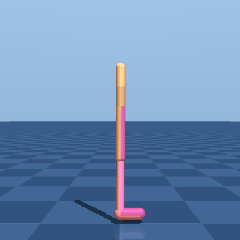

[codesign-gym] make_vec('Walker2d-v4', num_envs=16): instantiating
[walker2d] WARNING: torso_upper_offsettable_z: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[walker2d] WARNING: torso_lower_offsettable_z: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[walker2d] WARNING: foot_toe_offsettable_x: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[walker2d] WARNING: foot_left_toe_offsettable_x: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[codesign-gym] make_vec('Walker2d-v4', num_envs=16): success
[codesign-gym] make_vec('Walker2d-v4', num_envs=16): instantiating
[walker2d] WARNING: torso_upper_offsettable_z: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[walker2d] WARNING: torso_lower_offsettable_z: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[walker2d] WARNING: foot_toe_offsettable_x: 0.200 m undeformed, 0.037 m at its shortest, floored at 0.120 m
[walker2d] WARNING: foot_left_to

In [8]:
# load the policy and render a rollout, also print the eval score average of 16 rollouts
policy = load_result("runs/final_both.pt")
print("policy was trained on design:", policy.embodiment)

# one rendered rollout on the base body
frames, ep_return = rollout_frames(policy.act, base)
print(f"episode return on the base body: {ep_return:.1f}")
save_gif(frames, "runs/base_body_both.gif")

# one rendered rollout on the long legs
frames, ep_return = rollout_frames(policy.act, long_legs)
print(f"episode return on the long legs body: {ep_return:.1f}")
save_gif(frames, "runs/long_legs_both.gif")

# 16 deterministic rollouts on each body
base_returns = evaluate_policy(policy.act, ENV_ID, base, num_episodes=16, seed=random_seed)
long_returns = evaluate_policy(policy.act, ENV_ID, long_legs, num_episodes=16, seed=random_seed)
print(f"long legs: {long_returns.mean():.1f} ± {long_returns.std():.1f}")
print(f"base body:       {base_returns.mean():.1f} ± {base_returns.std():.1f}")